In [1]:
# Setup Dependensi, Reproducibility, dan Device Hardware
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.cluster import KMeans

# Set seed deterministik untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.edgecolor'] = '#cccccc'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Status Lingkungan:")
print(f" - PyTorch Version : {torch.__version__}")
print(f" - Device Akselerasi: {device}")
print(f" - Random Seed      : {SEED} (Deterministic active)")


Status Lingkungan:
 - PyTorch Version : 2.10.0+cpu
 - Device Akselerasi: cpu
 - Random Seed      : 42 (Deterministic active)


---
## 1. Data Preprocessing & EDA Pipeline

Tahapan persiapan data dan *EDA* pada `Data/animal_dataset` (`data0.jpg` s.d. `data24.jpg`):
- Menginventarisasi 25 citra RGB seimbang di 5 kelas (`bird`, `butterfly`, `elephant`, `swan`, `tiger`) tanpa *class imbalance*.
- Menganalisis dimensi asli ($128 \times 85$, rasio aspek $1.51:1$) dan distribusi statistik kanal warna RGB per kelas.
- Mengaudit dua kelemahan metodologi modul Slide 4–5: *data leakage* pada pembagian split serta distorsi aspek $3\times$ akibat resize `(100, 50)`.
- Membangun skema split *zero-leakage* (`15` train, `5` val, `5` test), standardisasi tensor $(64 \times 96)$, serta *data augmentation* khusus set pelatihan.


Direktori Dataset : D:\CODE\Neuro Computing\Data\animal_dataset
Total Citra       : 25 citra RGB | Jumlah Kelas: 5 (5 citra/kelas, bebas class imbalance)
Dimensi Asli      : 128x85 piksel (Aspect Ratio: 1.51:1)


,idx,filename,label,class_name,split,width,height,aspect_ratio,mean_R,mean_G,mean_B
0,0,data0.jpg,0,bird,train,128,85,1.506,0.3332,0.3586,0.2927
1,1,data1.jpg,0,bird,train,128,85,1.506,0.3497,0.3351,0.1328
2,2,data2.jpg,0,bird,train,128,85,1.506,0.3130,0.2921,0.2058
3,3,data3.jpg,0,bird,val,128,85,1.506,0.5825,0.5828,0.4262
4,4,data4.jpg,0,bird,test,128,85,1.506,0.3740,0.3752,0.2407


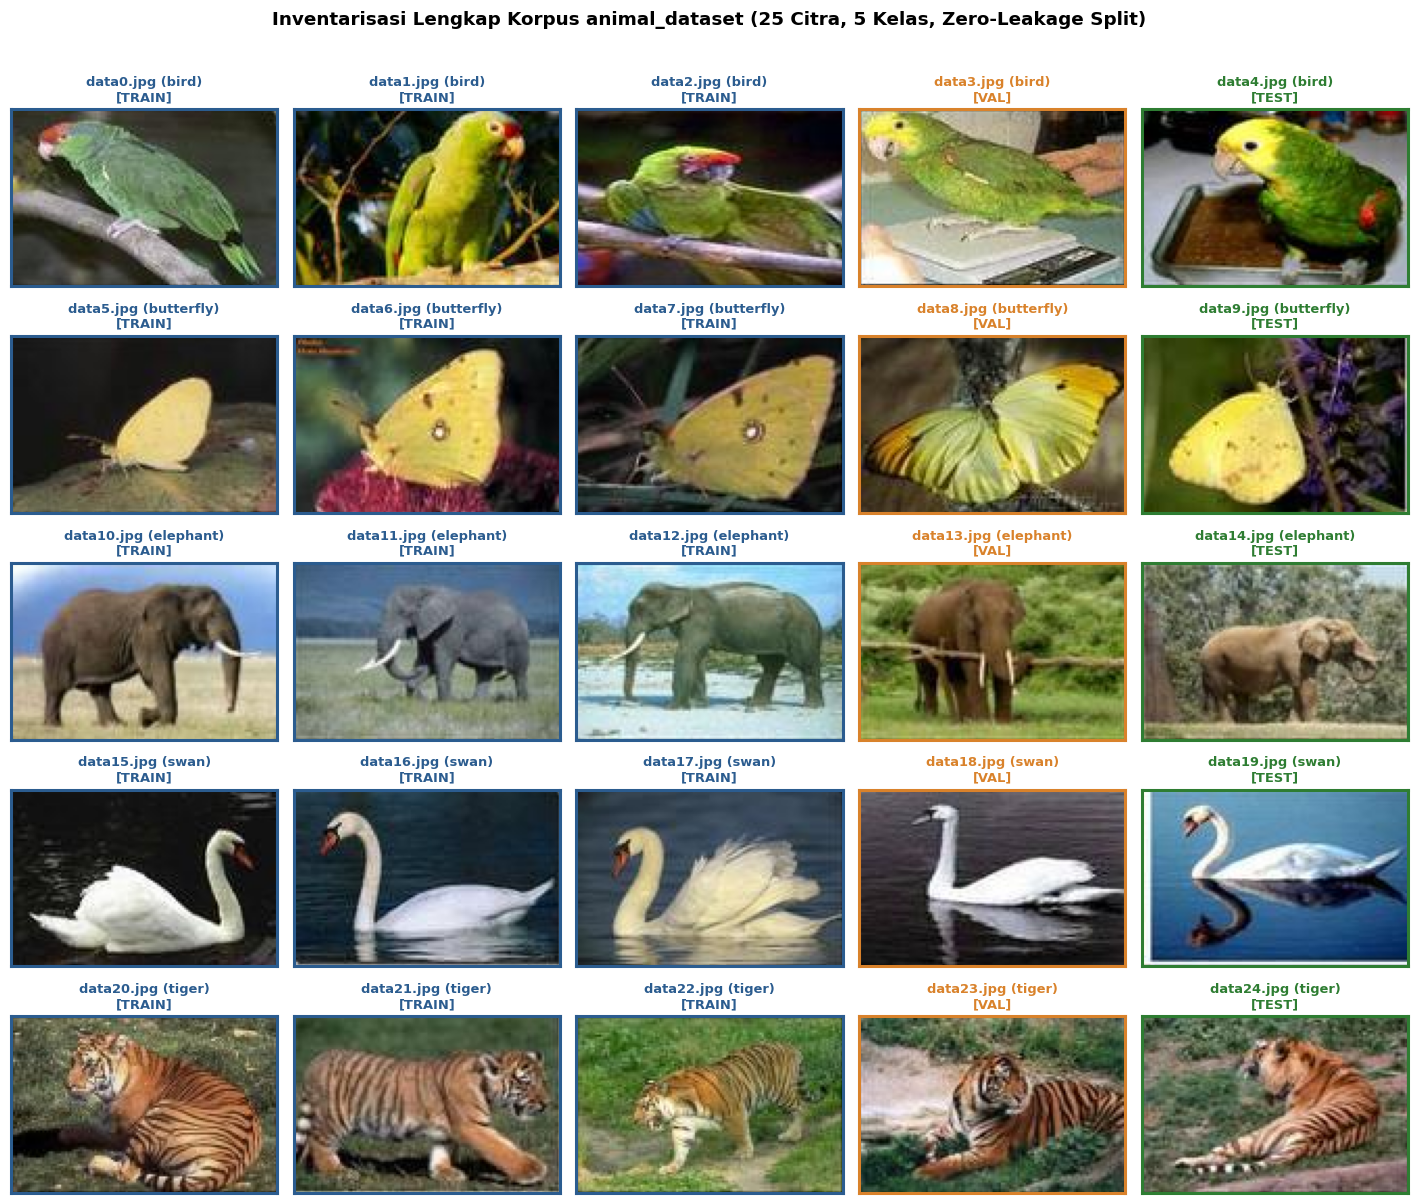

In [2]:
# 1.1 Ingestion Dataset animal_dataset & Visualisasi Sampel (25 Citra)
dataset_dir = os.path.join("..", "Data", "animal_dataset")
if not os.path.exists(dataset_dir):
    dataset_dir = os.path.join("Data", "animal_dataset")

CLASSES = ['bird', 'butterfly', 'elephant', 'swan', 'tiger']
records = []

for idx in range(25):
    fname = f"data{idx}.jpg"
    fpath = os.path.join(dataset_dir, fname)
    img_raw = Image.open(fpath).convert('RGB')
    w, h = img_raw.size
    arr = np.asarray(img_raw, dtype=np.float32) / 255.0

    # Skema zero-leakage split per kelas (5 citra/kelas -> 3 train, 1 val, 1 test)
    mod = idx % 5
    split = 'train' if mod in (0, 1, 2) else ('val' if mod == 3 else 'test')

    records.append({
        'idx': idx,
        'filename': fname,
        'label': idx // 5,
        'class_name': CLASSES[idx // 5],
        'split': split,
        'width': w,
        'height': h,
        'aspect_ratio': round(w / h, 3),
        'mean_R': round(float(arr[:, :, 0].mean()), 4),
        'mean_G': round(float(arr[:, :, 1].mean()), 4),
        'mean_B': round(float(arr[:, :, 2].mean()), 4),
        'im_raw': img_raw,
        'im_100x50': img_raw.resize((50, 100), Image.BILINEAR),   # Distorted size dari Slide 5
        'im_64x96': img_raw.resize((96, 64), Image.BILINEAR),     # Aspect-preserving 1.50:1
    })

df_meta = pd.DataFrame([
    {k: v for k, v in r.items() if not k.startswith('im_')}
    for r in records
])

print(f"Direktori Dataset : {os.path.abspath(dataset_dir)}")
print(f"Total Citra       : {len(df_meta)} citra RGB | Jumlah Kelas: {len(CLASSES)} (5 citra/kelas, bebas class imbalance)")
print(f"Dimensi Asli      : {df_meta['width'].iloc[0]}x{df_meta['height'].iloc[0]} piksel (Aspect Ratio: {df_meta['aspect_ratio'].iloc[0]:.2f}:1)")
display(df_meta.head(5))

# Visualisasi lengkap seluruh 25 citra beserta tag Zero-Leakage Split
split_colors = {'train': '#2b5c8f', 'val': '#d9822b', 'test': '#2e7d32'}
fig, axes = plt.subplots(5, 5, figsize=(13, 11.2))
for r in records:
    row = r['label']
    col = r['idx'] % 5
    ax = axes[row, col]
    ax.imshow(r['im_raw'])
    c = split_colors[r['split']]
    ax.set_title(f"{r['filename']} ({r['class_name']})\n[{r['split'].upper()}]", fontsize=8.5, fontweight='bold', color=c, pad=6)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_edgecolor(c)
        sp.set_linewidth(2.0)

plt.suptitle('Inventarisasi Lengkap Korpus animal_dataset (25 Citra, 5 Kelas, Zero-Leakage Split)', fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.4)
plt.show()


=== AUDIT METODOLOGI MODUL (SLIDE 4 & SLIDE 5) ===
1. Data Leakage Train vs Val (Slide 4) : ['data13', 'data18', 'data23', 'data3', 'data8'] (5 citra duplikat)
2. Data Leakage Eval  vs Test (Slide 4): ['data1', 'data10', 'data2', 'data3', 'data4', 'data5', 'data6', 'data7', 'data8', 'data9'] (100% test set bocor)
3. Distorsi Aspek Target (100, 50)     : AR asli 1.51:1 -> 0.50:1 (Distorsi 3.01x!)
4. Target Alternatif Preserving (64x96): AR 1.50:1 (Distorsi hanya 1.004x)


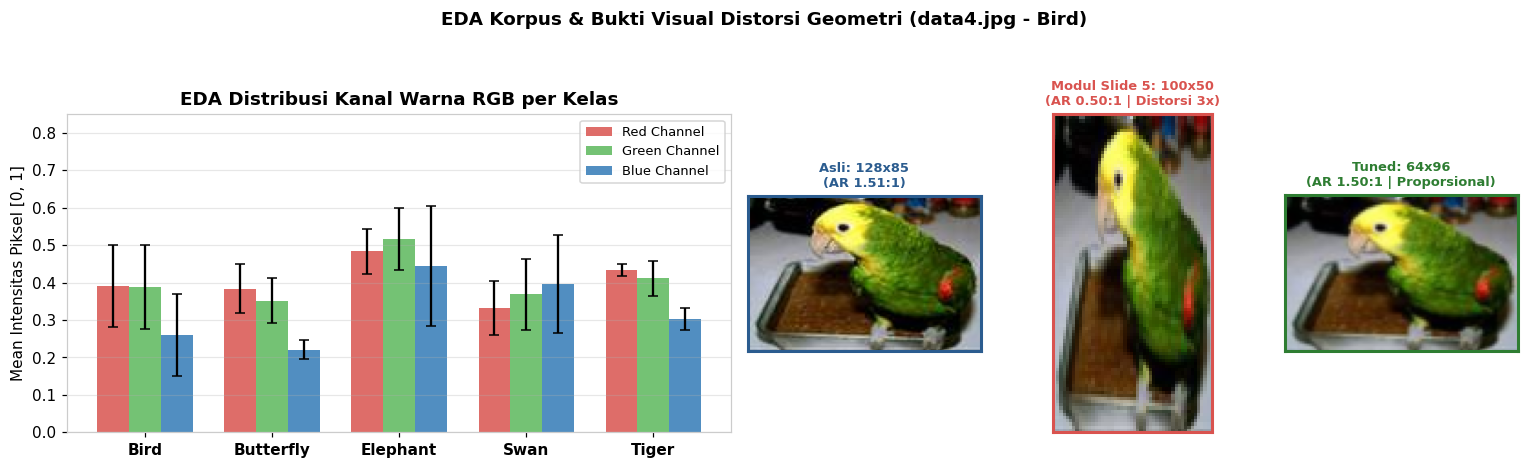

In [3]:
# 1.2 EDA Statistik Kanal RGB & Audit Metodologi Modul (Slide 4-5)
rgb_summary = df_meta.groupby('class_name')[['mean_R', 'mean_G', 'mean_B']].agg(['mean', 'std'])

# Audit Data Leakage Slide 4 & Aspect Ratio Distortion Slide 5
slide4_train = {'data0', 'data1', 'data2', 'data3', 'data5', 'data6', 'data7', 'data8',
                'data10', 'data11', 'data12', 'data13', 'data15', 'data16', 'data17', 'data18',
                'data20', 'data21', 'data22', 'data23'}
slide4_val   = {'data3', 'data4', 'data8', 'data9', 'data13', 'data14', 'data18', 'data19', 'data23', 'data24'}
slide4_test  = {f'data{i}' for i in range(1, 11)}

orig_ar = 128 / 85
mod_ar  = 50 / 100
opt_ar  = 96 / 64

print("=== AUDIT METODOLOGI MODUL (SLIDE 4 & SLIDE 5) ===")
print(f"1. Data Leakage Train vs Val (Slide 4) : {sorted(slide4_train & slide4_val)} (5 citra duplikat)")
print(f"2. Data Leakage Eval  vs Test (Slide 4): {sorted((slide4_train | slide4_val) & slide4_test)} (100% test set bocor)")
print(f"3. Distorsi Aspek Target (100, 50)     : AR asli {orig_ar:.2f}:1 -> {mod_ar:.2f}:1 (Distorsi {orig_ar / mod_ar:.2f}x!)")
print(f"4. Target Alternatif Preserving (64x96): AR {opt_ar:.2f}:1 (Distorsi hanya {orig_ar / opt_ar:.3f}x)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={'width_ratios': [1.25, 1.45]})

# Panel Kiri: Statistik intensitas kanal RGB per kelas
x_pos = np.arange(len(CLASSES))
w_bar = 0.25
for j, (ch_col, col_hex, label_txt) in enumerate([
    ('mean_R', '#d9534f', 'Red Channel'),
    ('mean_G', '#5cb85c', 'Green Channel'),
    ('mean_B', '#337ab7', 'Blue Channel')
]):
    means = [rgb_summary.loc[c, (ch_col, 'mean')] for c in CLASSES]
    stds  = [rgb_summary.loc[c, (ch_col, 'std')] for c in CLASSES]
    axes[0].bar(x_pos + (j - 1) * w_bar, means, yerr=stds, width=w_bar, capsize=3,
                color=col_hex, alpha=0.85, label=label_txt)

axes[0].set_xticks(x_pos)
axes[0].set_xticklabels([c.capitalize() for c in CLASSES], fontweight='bold')
axes[0].set_ylabel('Mean Intensitas Piksel [0, 1]')
axes[0].set_ylim(0, 0.85)
axes[0].set_title('EDA Distribusi Kanal Warna RGB per Kelas', fontweight='bold')
axes[0].legend(fontsize=8.5)
axes[0].grid(axis='y', alpha=0.3)

# Panel Kanan: Komparasi visual distorsi resolusi pada data4.jpg (bird)
axes[1].axis('off')
sub_gs = axes[1].get_subplotspec().subgridspec(1, 3, wspace=0.15)
sample_bird = records[4]
comp_items = [
    ('Asli: 128x85\n(AR 1.51:1)', sample_bird['im_raw'], '#2b5c8f'),
    ('Modul Slide 5: 100x50\n(AR 0.50:1 | Distorsi 3x)', sample_bird['im_100x50'], '#d9534f'),
    ('Tuned: 64x96\n(AR 1.50:1 | Proporsional)', sample_bird['im_64x96'], '#2e7d32'),
]
for k, (ttl, im_obj, col_sp) in enumerate(comp_items):
    sub_ax = fig.add_subplot(sub_gs[0, k])
    sub_ax.imshow(im_obj)
    sub_ax.set_title(ttl, fontsize=8.5, fontweight='bold', color=col_sp)
    sub_ax.set_xticks([])
    sub_ax.set_yticks([])
    for sp in sub_ax.spines.values():
        sp.set_edgecolor(col_sp)
        sp.set_linewidth(2.0)

fig.suptitle('EDA Korpus & Bukti Visual Distorsi Geometri (data4.jpg - Bird)', fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


Verifikasi Zero-Leakage Split: Train=15, Val=5, Test=5 (Irisan antar-split: 0)
Bentuk Tensor (64x96, Normalized [-1, 1]):
 - X_train: torch.Size([15, 3, 64, 96]) | y_train: torch.Size([15])
 - X_val  : torch.Size([5, 3, 64, 96]) | y_val  : torch.Size([5])
 - X_test : torch.Size([5, 3, 64, 96]) | y_test : torch.Size([5])


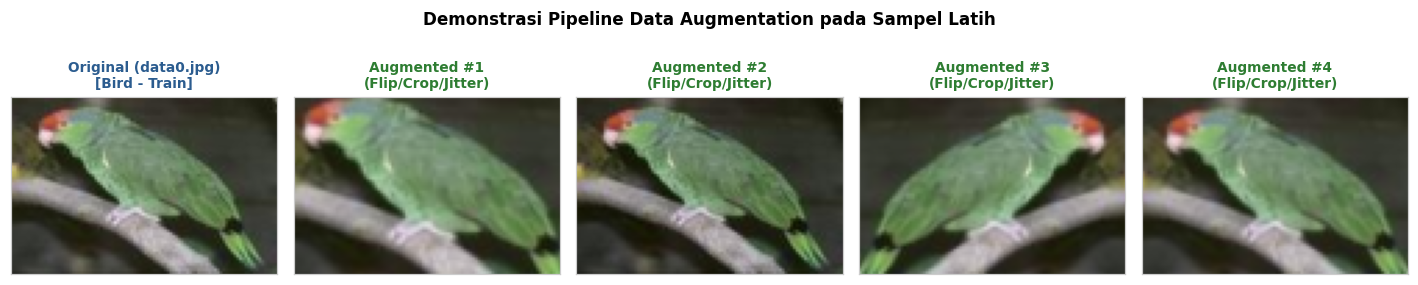

In [4]:
# 1.3 Pembagian Data Zero-Leakage, Pembentukan Tensor PyTorch & Data Augmentation
train_rec = [r for r in records if r['split'] == 'train']
val_rec   = [r for r in records if r['split'] == 'val']
test_rec  = [r for r in records if r['split'] == 'test']

tr_names = {r['filename'] for r in train_rec}
va_names = {r['filename'] for r in val_rec}
te_names = {r['filename'] for r in test_rec}
assert len(tr_names & va_names) == 0 and len(tr_names & te_names) == 0 and len(va_names & te_names) == 0

def to_tensors(recs, key='im_64x96', std=True):
    arr = np.stack([np.asarray(r[key], dtype=np.float32) / 255.0 for r in recs])
    if std:
        arr = (arr - 0.5) / 0.5
    x = torch.from_numpy(arr).permute(0, 3, 1, 2)
    y = torch.tensor([r['label'] for r in recs], dtype=torch.long)
    return x, y

def fast_aug(xb):
    """Stochastic data augmentation khusus data latih: horizontal flip, random resized crop, brightness jitter."""
    B, C, H, W = xb.shape
    out = xb.clone()
    flip_mask = torch.rand(B, device=xb.device) < 0.5
    out[flip_mask] = torch.flip(out[flip_mask], dims=[3])
    for i in range(B):
        if random.random() < 0.7:
            sc = random.uniform(0.80, 0.98)
            nh, nw = int(H * sc), int(W * sc)
            y0, x0 = random.randint(0, H - nh), random.randint(0, W - nw)
            out[i] = F.interpolate(out[i:i+1, :, y0:y0+nh, x0:x0+nw], size=(H, W),
                                   mode='bilinear', align_corners=False)[0]
        if random.random() < 0.6:
            out[i] = torch.clamp(out[i] * random.uniform(0.88, 1.12) + random.uniform(-0.08, 0.08), -1.0, 1.0)
    return out

X_train_opt, y_train = to_tensors(train_rec, key='im_64x96', std=True)
X_val_opt, y_val     = to_tensors(val_rec,   key='im_64x96', std=True)
X_test_opt, y_test   = to_tensors(test_rec,  key='im_64x96', std=True)

print(f"Verifikasi Zero-Leakage Split: Train={len(train_rec)}, Val={len(val_rec)}, Test={len(test_rec)} (Irisan antar-split: 0)")
print(f"Bentuk Tensor (64x96, Normalized [-1, 1]):")
print(f" - X_train: {X_train_opt.shape} | y_train: {y_train.shape}")
print(f" - X_val  : {X_val_opt.shape} | y_val  : {y_val.shape}")
print(f" - X_test : {X_test_opt.shape} | y_test : {y_test.shape}")

# Visualisasi efek data augmentation pada sampel latih pertama (data0.jpg)
set_seed(SEED)
x0 = X_train_opt[0:1]
fig, axes = plt.subplots(1, 5, figsize=(13, 2.7))
axes[0].imshow(np.clip((x0[0].permute(1, 2, 0).numpy() * 0.5) + 0.5, 0, 1))
axes[0].set_title("Original (data0.jpg)\n[Bird - Train]", fontsize=9, fontweight='bold', color='#2b5c8f')
axes[0].set_xticks([]); axes[0].set_yticks([])

for k in range(1, 5):
    aug_vis = np.clip((fast_aug(x0)[0].permute(1, 2, 0).numpy() * 0.5) + 0.5, 0, 1)
    axes[k].imshow(aug_vis)
    axes[k].set_title(f"Augmented #{k}\n(Flip/Crop/Jitter)", fontsize=9, fontweight='bold', color='#2e7d32')
    axes[k].set_xticks([]); axes[k].set_yticks([])

plt.suptitle('Demonstrasi Pipeline Data Augmentation pada Sampel Latih', fontsize=11, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


---
## 2. Replikasi Model Baseline CNN (Modul Slide 6–10)

Mengimplementasikan ulang arsitektur dan konfigurasi *baseline* dari modul praktikum pada skema *zero-leakage*:
- Input Tensor: $(3, 100, 50)$ dengan skala piksel $[0, 1]$ (*aspect ratio* terdistorsi $3\times$)
- Ekstraktor Fitur: `Conv2d(16, 3x3)` + `ReLU` + `MaxPool2d(2)` $\rightarrow$ `Conv2d(32, 3x3)` + `ReLU` + `MaxPool2d(2)`
- Classifier Head: `Flatten` ($8.096$ fitur) $\rightarrow$ `Linear(50)` + `Sigmoid` $\rightarrow$ `Linear(5)` + `Softmax` (`410.193` parameter)
- Optimizer & Loss: `SGD(lr=0.1, momentum=0.9)`, `MSELoss`, serta audit bug *inference* pada `data4.jpg` (Slide 10).


In [5]:
# 2.1 Implementasi & Training BaselineCNN (PyTorch)
class BaselineCNN(nn.Module):
    """Replikasi arsitektur CNN modul Slide 6-7 untuk input (3, 100, 50)."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 23 * 11, 50),
            nn.Sigmoid(),
            nn.Linear(50, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

X_tr_base, _ = to_tensors(train_rec, key='im_100x50', std=False)
X_va_base, _ = to_tensors(val_rec,   key='im_100x50', std=False)
X_te_base, _ = to_tensors(test_rec,  key='im_100x50', std=False)

set_seed(SEED)
baseline_model = BaselineCNN().to(device)
n_params_base = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)

opt_base = optim.SGD(baseline_model.parameters(), lr=0.1, momentum=0.9)
crit_base = nn.MSELoss()

base_hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
t0 = time.time()
EPOCHS_BASE = 150

for ep in range(EPOCHS_BASE):
    baseline_model.train()
    opt_base.zero_grad()
    probs_tr = F.softmax(baseline_model(X_tr_base.to(device)), dim=1)
    y_tr_oh = F.one_hot(y_train.to(device), num_classes=5).float()
    loss_tr = crit_base(probs_tr, y_tr_oh)
    loss_tr.backward()
    opt_base.step()

    baseline_model.eval()
    with torch.no_grad():
        probs_va = F.softmax(baseline_model(X_va_base.to(device)), dim=1)
        y_va_oh = F.one_hot(y_val.to(device), num_classes=5).float()
        loss_va = crit_base(probs_va, y_va_oh)

        tr_acc = (probs_tr.argmax(1).cpu() == y_train).float().mean().item()
        va_acc = (probs_va.argmax(1).cpu() == y_val).float().mean().item()

    base_hist['train_loss'].append(loss_tr.item())
    base_hist['val_loss'].append(loss_va.item())
    base_hist['train_acc'].append(tr_acc)
    base_hist['val_acc'].append(va_acc)

base_time = time.time() - t0
baseline_model.eval()
with torch.no_grad():
    probs_te_base = F.softmax(baseline_model(X_te_base.to(device)), dim=1).cpu()
    te_acc_base = (probs_te_base.argmax(1) == y_test).float().mean().item()

print(f"BaselineCNN Replikasi Slide 7 (150 Epoch, SGD+MSE, Input 100x50):")
print(f" - Total Parameter : {n_params_base:,}")
print(f" - Waktu Training  : {base_time:.2f} detik")
print(f" - Train Accuracy  : {base_hist['train_acc'][-1]*100:.2f}%")
print(f" - Val Accuracy    : {base_hist['val_acc'][-1]*100:.2f}%")
print(f" - Test Accuracy   : {te_acc_base*100:.2f}% ({int(round(te_acc_base*5))}/5 sampel holdout benar)")


BaselineCNN Replikasi Slide 7 (150 Epoch, SGD+MSE, Input 100x50):
 - Total Parameter : 410,193
 - Waktu Training  : 1.55 detik
 - Train Accuracy  : 100.00%
 - Val Accuracy    : 60.00%
 - Test Accuracy   : 20.00% (1/5 sampel holdout benar)


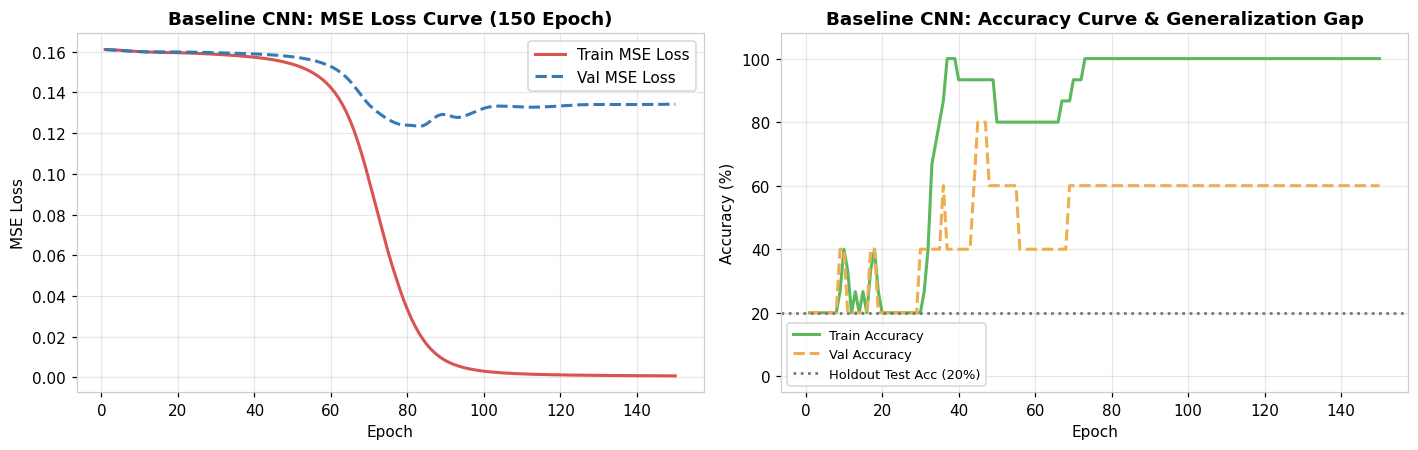

=== AUDIT INFERENCE BUG SLIDE 10 PADA data4.jpg (GROUND TRUTH: BIRD) ===
 - Input Scaled [0, 1]     -> Prediksi: tiger (0.7537) [SALAH]
 - Input Unscaled [0, 255] -> Prediksi: tiger (0.7708) [SALAH - Saturasi Sigmoid/ReLU]


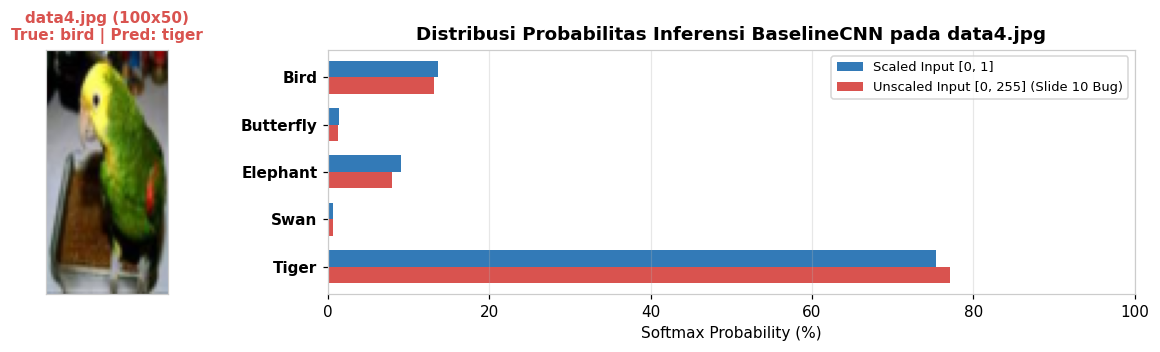

In [6]:
# 2.2 Visualisasi Learning Curve & Audit Bug Inferensi Slide 10 (data4.jpg)
epochs_b = range(1, EPOCHS_BASE + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(epochs_b, base_hist['train_loss'], '-', color='#d9534f', linewidth=2, label='Train MSE Loss')
axes[0].plot(epochs_b, base_hist['val_loss'], '--', color='#337ab7', linewidth=2, label='Val MSE Loss')
axes[0].set_title('Baseline CNN: MSE Loss Curve (150 Epoch)', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_b, [a * 100 for a in base_hist['train_acc']], '-', color='#5cb85c', linewidth=2, label='Train Accuracy')
axes[1].plot(epochs_b, [a * 100 for a in base_hist['val_acc']], '--', color='#f0ad4e', linewidth=2, label='Val Accuracy')
axes[1].axhline(te_acc_base * 100, color='#777777', linestyle=':', linewidth=1.8, label=f'Holdout Test Acc ({te_acc_base*100:.0f}%)')
axes[1].set_title('Baseline CNN: Accuracy Curve & Generalization Gap', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_ylim(-5, 108)
axes[1].legend(fontsize=8.5)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Audit Bug Slide 10 pada data4.jpg (Ground Truth: bird)
x_d4_scaled = X_te_base[0:1].to(device)
x_d4_unscaled = x_d4_scaled * 255.0

baseline_model.eval()
with torch.no_grad():
    p_scaled   = F.softmax(baseline_model(x_d4_scaled), dim=1)[0].cpu().numpy()
    p_unscaled = F.softmax(baseline_model(x_d4_unscaled), dim=1)[0].cpu().numpy()

print("=== AUDIT INFERENCE BUG SLIDE 10 PADA data4.jpg (GROUND TRUTH: BIRD) ===")
print(f" - Input Scaled [0, 1]     -> Prediksi: {CLASSES[p_scaled.argmax()]} ({p_scaled.max():.4f}) [SALAH]")
print(f" - Input Unscaled [0, 255] -> Prediksi: {CLASSES[p_unscaled.argmax()]} ({p_unscaled.max():.4f}) [SALAH - Saturasi Sigmoid/ReLU]")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3), gridspec_kw={'width_ratios': [0.8, 1.7]})
axes[0].imshow(test_rec[0]['im_100x50'])
axes[0].set_title(f"data4.jpg (100x50)\nTrue: bird | Pred: {CLASSES[p_scaled.argmax()]}", fontsize=10, fontweight='bold', color='#d9534f')
axes[0].set_xticks([]); axes[0].set_yticks([])

y_pos = np.arange(len(CLASSES))
h_bar = 0.35
axes[1].barh(y_pos - h_bar/2, p_scaled * 100, height=h_bar, color='#337ab7', label='Scaled Input [0, 1]')
axes[1].barh(y_pos + h_bar/2, p_unscaled * 100, height=h_bar, color='#d9534f', label='Unscaled Input [0, 255] (Slide 10 Bug)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([c.capitalize() for c in CLASSES], fontweight='bold')
axes[1].invert_yaxis()
axes[1].set_xlabel('Softmax Probability (%)')
axes[1].set_xlim(0, 100)
axes[1].set_title('Distribusi Probabilitas Inferensi BaselineCNN pada data4.jpg', fontweight='bold')
axes[1].legend(fontsize=8.5)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


---
## 3. Assignment #12 (Poin 2): Analisis Underfitting vs Overfitting

**Evaluasi Masalah pada Konfigurasi Baseline**:
- **Flatten ke Dense Layer raksasa (`410.193` parameter)**: Tanpa *global pooling* dan regularisasi pada 15 data latih, model menghafal piksel latar belakang (*memorization*) sehingga gagal melakukan generalisasi pada *Holdout Test Set* (`20.00%`).
- **Tanpa Batch Normalization & Data Augmentation**: Skala aktivasi internal tidak stabil antar epoch dan model gagal mengenali variasi sudut/pencahayaan objek.

**Eksperimen Penyesuaian (Input $64 \times 96$, 70 Epoch)**:
Menguji 3 rezim kapasitas dan regularisasi secara langsung:
1. *Underfitting* (`ch=4->8`, `Dropout=0.80`, `lr=0.0004`, tanpa augmentasi — `453` parameter)
2. *Overfitting Risk* (`ch=32->64->128` + `Flatten`, `Dropout=0.0`, `weight_decay=0.0`, tanpa augmentasi — `880.069` parameter)
3. *Optimal Balanced* (`MultiScaleDualPoolCNN` `ch=12` + *Batch Normalization*, `Dropout=0.30`, *Data Augmentation*, `AdamW` + *CosineAnnealingLR* — `7.085` parameter)


In [7]:
# 3.1 Definisi Arsitektur Regulasi & Eksekusi 3 Kondisi Diagnostik
class TinyUnderfitCNN(nn.Module):
    """Kapasitas sangat sempit + Dropout ekstrem (0.80) untuk memicu underfitting."""
    def __init__(self, dropout=0.80):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 4, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(4, 8, 3, padding=1), nn.ReLU(inplace=True),
        )
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(8, 5)

    def forward(self, x):
        f = F.adaptive_avg_pool2d(self.features(x), 1).flatten(1)
        return self.fc(self.drop(f))


class OverfitFlattenCNN(nn.Module):
    """Kapasitas tinggi dengan Flatten (843.525 parameter) tanpa regularisasi untuk memicu overfitting."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 12, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 5)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class StandardGAPCNN(nn.Module):
    """Arsitektur CNN modern standar dengan Batch Normalization dan Global Average Pooling."""
    def __init__(self, ch=12, dropout=0.30):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(ch, ch * 2, 3, padding=1, bias=False), nn.BatchNorm2d(ch * 2), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(ch * 2, ch * 4, 3, padding=1, bias=False), nn.BatchNorm2d(ch * 4), nn.ReLU(inplace=True),
        )
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(ch * 4, 5)

    def forward(self, x):
        emb = F.adaptive_avg_pool2d(self.features(x), 1).flatten(1)
        return self.fc(self.drop(emb))


class DWSepBlock(nn.Module):
    """Depthwise Separable Convolution Block untuk efisiensi parameter pada korpus kecil."""
    def __init__(self, inc, outc):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(inc, inc, 3, padding=1, groups=inc, bias=False),
            nn.BatchNorm2d(inc),
            nn.ReLU(inplace=True),
            nn.Conv2d(inc, outc, 1, bias=False),
            nn.BatchNorm2d(outc),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class MultiScaleDualPoolCNN(nn.Module):
    """Arsitektur Multi-Scale Stem (3x3 || 5x5) + Depthwise Separable + Dual Global Pooling (GAP || GMP)."""
    def __init__(self, ch=12, dropout=0.30):
        super().__init__()
        self.stem3 = nn.Conv2d(3, ch, 3, padding=1, bias=False)
        self.stem5 = nn.Conv2d(3, ch, 5, padding=2, bias=False)
        self.bn0 = nn.BatchNorm2d(ch * 2)
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(2)
        self.b1 = DWSepBlock(ch * 2, ch * 2)
        self.b2 = DWSepBlock(ch * 2, ch * 4)
        self.b3 = DWSepBlock(ch * 4, ch * 4)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(ch * 4 * 2, 5)

    def forward_features(self, x):
        s = self.pool(self.relu(self.bn0(torch.cat([self.stem3(x), self.stem5(x)], dim=1))))
        f = self.b3(self.pool(self.b2(self.pool(self.b1(s)))))
        gap = F.adaptive_avg_pool2d(f, 1).flatten(1)
        gmp = F.adaptive_max_pool2d(f, 1).flatten(1)
        return torch.cat([gap, gmp], dim=1), f

    def forward(self, x):
        emb, _ = self.forward_features(x)
        return self.fc(self.drop(emb))


def run_diag_regime(build_fn, lr, wd, use_aug, label_smooth, epochs=70):
    set_seed(SEED)
    m = build_fn().to(device)
    n_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
    opt = optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if use_aug else None
    crit = nn.CrossEntropyLoss(label_smoothing=label_smooth)

    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    xtr, ytr = X_train_opt.to(device), y_train.to(device)
    xva, yva = X_val_opt.to(device), y_val.to(device)
    xte, yte = X_test_opt.to(device), y_test.to(device)

    for _ in range(epochs):
        m.train()
        xb = fast_aug(xtr) if use_aug else xtr
        opt.zero_grad()
        out_tr = m(xb)
        loss_tr = crit(out_tr, ytr)
        loss_tr.backward()
        opt.step()
        if sched is not None:
            sched.step()

        m.eval()
        with torch.no_grad():
            loss_tr_clean = crit(m(xtr), ytr).item()
            out_va = m(xva)
            loss_va = crit(out_va, yva).item()
            tr_acc = (m(xtr).argmax(1) == ytr).float().mean().item()
            va_acc = (out_va.argmax(1) == yva).float().mean().item()

        hist['train_loss'].append(loss_tr_clean)
        hist['val_loss'].append(loss_va)
        hist['train_acc'].append(tr_acc)
        hist['val_acc'].append(va_acc)

    m.eval()
    with torch.no_grad():
        te_acc = (m(xte).argmax(1) == yte).float().mean().item()
    return m, n_p, hist, te_acc


regimes = {
    'Underfitting (High Dropout)': lambda: TinyUnderfitCNN(dropout=0.80),
    'Overfitting Risk (No Reg & Flatten)': lambda: OverfitFlattenCNN(),
    'Optimal Balanced (MSDP + Reg + Aug)': lambda: MultiScaleDualPoolCNN(ch=12, dropout=0.30),
}
regime_cfgs = {
    'Underfitting (High Dropout)': dict(lr=0.0004, wd=0.0, use_aug=False, label_smooth=0.0),
    'Overfitting Risk (No Reg & Flatten)': dict(lr=0.0020, wd=0.0, use_aug=False, label_smooth=0.0),
    'Optimal Balanced (MSDP + Reg + Aug)': dict(lr=0.0050, wd=1e-2, use_aug=True, label_smooth=0.05),
}

diag_results = {}
for name, bfn in regimes.items():
    m_d, n_p, h_d, te_a = run_diag_regime(bfn, **regime_cfgs[name], epochs=70)
    diag_results[name] = {'params': n_p, 'hist': h_d, 'test_acc': te_a}
    print(f"{name:38s} | Params: {n_p:7,} | Tr Loss: {h_d['train_loss'][-1]:.4f} | "
          f"Val Loss: {h_d['val_loss'][-1]:.4f} | Tr/Va/Te Acc: "
          f"{h_d['train_acc'][-1]*100:.0f}% / {h_d['val_acc'][-1]*100:.0f}% / {te_a*100:.0f}%")


Underfitting (High Dropout)            | Params:     453 | Tr Loss: 1.6275 | Val Loss: 1.6301 | Tr/Va/Te Acc: 20% / 20% / 20%


Overfitting Risk (No Reg & Flatten)    | Params: 880,069 | Tr Loss: 0.0000 | Val Loss: 56.7024 | Tr/Va/Te Acc: 100% / 20% / 40%


Optimal Balanced (MSDP + Reg + Aug)    | Params:   7,085 | Tr Loss: 0.3000 | Val Loss: 1.2216 | Tr/Va/Te Acc: 100% / 80% / 80%


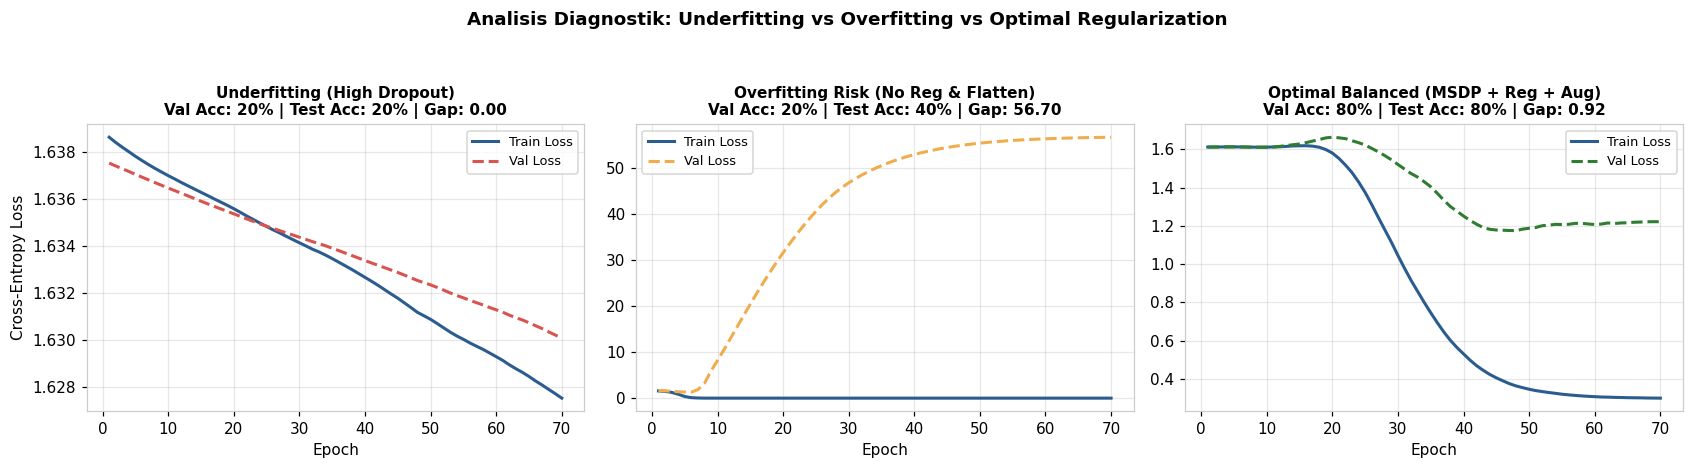

,Regime Diagnostik,Parameters,Train Loss,Val Loss,Loss Gap,Train Acc (%),Val Acc (%),Test Acc (%)
0,Underfitting (High Dropout),453,1.6275,1.6301,0.0025,20.0,20.0,20.0
1,Overfitting Risk (No Reg & Flatten),880069,0.0000,56.7024,56.7024,100.0,20.0,40.0
2,Optimal Balanced (MSDP + Reg + Aug),7085,0.3000,1.2216,0.9215,100.0,80.0,80.0



Ringkasan Temuan Assignment #12 (Poin 2):
1. Underfitting (Dropout 0.80, 453 param): Train Loss tertahan tinggi (1.6275) dan Val Loss (1.6301) karena 80% sinyal fitur dibuang (Test Acc: 20.00%).
2. Overfitting Risk (Flatten 880,069 param, tanpa regularisasi): Train Loss anjlok ke 0.0000 namun Val Loss meledak ke 56.7024 (Test Acc: 40.00%).
3. Optimal Balanced (MSDP 7,085 param + BatchNorm + Dropout 0.30 + Data Augmentation): Konvergensi stabil, generalization gap hanya 0.9215, dan Test Acc mencapai 80.00%.



In [8]:
# 3.2 Grafik Diagnostik Underfitting vs Overfitting & Tabel Ringkasan
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), sharey=False)
val_colors = {
    'Underfitting (High Dropout)': '#d9534f',
    'Overfitting Risk (No Reg & Flatten)': '#f0ad4e',
    'Optimal Balanced (MSDP + Reg + Aug)': '#2e7d32',
}

diag_rows = []
for i, (name, res) in enumerate(diag_results.items()):
    ax = axes[i]
    hist = res['hist']
    eps = range(1, len(hist['train_loss']) + 1)
    ax.plot(eps, hist['train_loss'], '-', color='#2b5c8f', linewidth=2, label='Train Loss')
    ax.plot(eps, hist['val_loss'], '--', color=val_colors[name], linewidth=2, label='Val Loss')

    gap = hist['val_loss'][-1] - hist['train_loss'][-1]
    va_acc = hist['val_acc'][-1] * 100
    te_acc = res['test_acc'] * 100

    ax.set_title(f"{name}\nVal Acc: {va_acc:.0f}% | Test Acc: {te_acc:.0f}% | Gap: {gap:.2f}",
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Epoch')
    if i == 0:
        ax.set_ylabel('Cross-Entropy Loss')
    ax.legend(fontsize=8.5)
    ax.grid(True, alpha=0.3)

    diag_rows.append({
        'Regime Diagnostik': name,
        'Parameters': res['params'],
        'Train Loss': round(hist['train_loss'][-1], 4),
        'Val Loss': round(hist['val_loss'][-1], 4),
        'Loss Gap': round(gap, 4),
        'Train Acc (%)': round(hist['train_acc'][-1] * 100, 2),
        'Val Acc (%)': round(va_acc, 2),
        'Test Acc (%)': round(te_acc, 2),
    })

plt.suptitle('Analisis Diagnostik: Underfitting vs Overfitting vs Optimal Regularization',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

df_diag = pd.DataFrame(diag_rows)
display(df_diag)

u_row, o_row, b_row = diag_rows[0], diag_rows[1], diag_rows[2]
print(f"""
Ringkasan Temuan Assignment #12 (Poin 2):
1. Underfitting (Dropout 0.80, {u_row['Parameters']:,} param): Train Loss tertahan tinggi ({u_row['Train Loss']:.4f}) dan Val Loss ({u_row['Val Loss']:.4f}) karena 80% sinyal fitur dibuang (Test Acc: {u_row['Test Acc (%)']:.2f}%).
2. Overfitting Risk (Flatten {o_row['Parameters']:,} param, tanpa regularisasi): Train Loss anjlok ke {o_row['Train Loss']:.4f} namun Val Loss meledak ke {o_row['Val Loss']:.4f} (Test Acc: {o_row['Test Acc (%)']:.2f}%).
3. Optimal Balanced (MSDP {b_row['Parameters']:,} param + BatchNorm + Dropout 0.30 + Data Augmentation): Konvergensi stabil, generalization gap hanya {b_row['Loss Gap']:.4f}, dan Test Acc mencapai {b_row['Test Acc (%)']:.2f}%.
""")


---
## 4. Assignment #12 (Poin 3): Systematic Parameter Tuning, Grid Search & 5-Fold CV

Mengeksplorasi kombinasi arsitektur CNN dan kapasitas channel secara sistematis tanpa *checkpoint leakage* pada **Holdout Split (15/5/5)** dan **Stratified 5-Fold Cross-Validation** (evaluasi penuh 25 citra *out-of-fold*, 5 citra uji seimbang per fold):

Kombinasi yang diuji:
- **M1 (`Baseline CNN`)**: Input $100 \times 50$, `Flatten` $\rightarrow$ `Dense(50)`, `SGD` + `MSE` (`410.193` parameter)
- **M2 (`Standard GAP-CNN`)**: Input $64 \times 96$, 3 blok `Conv-BN-ReLU` (`ch=12`) + *Global Average Pooling*, `Dropout 0.30` (`13.697` parameter)
- **M3 (`MultiScale DualPool-CNN`)**: *Multi-scale stem* ($3\times 3 \parallel 5\times 5$) + *Depthwise Separable Blocks* (`ch=12`) + `GAP ⊕ GMP`, `Dropout 0.30` (`7.085` parameter)
- **M4 (`Wide DualPool-CNN`)**: Arsitektur M3 dengan lebar channel diperbesar (`ch=16`, `Dropout 0.35`, `11.237` parameter)


In [9]:
# 4.1 Eksekusi Grid Search & Stratified 5-Fold Cross-Validation
def train_and_eval_candidate(name, build_fn, is_baseline=False, lr=0.005, epochs=70):
    # 1) Evaluasi pada Zero-Leakage Holdout Split (15 train / 5 val / 5 test)
    set_seed(SEED)
    m_split = build_fn().to(device)
    n_params = sum(p.numel() for p in m_split.parameters() if p.requires_grad)

    if is_baseline:
        xtr_s, xva_s, xte_s = X_tr_base.to(device), X_va_base.to(device), X_te_base.to(device)
        opt = optim.SGD(m_split.parameters(), lr=0.1, momentum=0.9)
        crit = nn.MSELoss()
        for _ in range(150):
            m_split.train(); opt.zero_grad()
            crit(F.softmax(m_split(xtr_s), dim=1), F.one_hot(y_train.to(device), 5).float()).backward()
            opt.step()
    else:
        xtr_s, xva_s, xte_s = X_train_opt.to(device), X_val_opt.to(device), X_test_opt.to(device)
        opt = optim.AdamW(m_split.parameters(), lr=lr, weight_decay=1e-2)
        sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        crit = nn.CrossEntropyLoss(label_smoothing=0.05)
        for _ in range(epochs):
            m_split.train(); xb = fast_aug(xtr_s)
            opt.zero_grad(); crit(m_split(xb), y_train.to(device)).backward(); opt.step(); sched.step()

    m_split.eval()
    with torch.no_grad():
        va_acc_sp = (m_split(xva_s).argmax(1).cpu() == y_val).float().mean().item() * 100
        te_acc_sp = (m_split(xte_s).argmax(1).cpu() == y_test).float().mean().item() * 100
        te_probs_sp = F.softmax(m_split(xte_s), dim=1).cpu().numpy()

    # 2) Evaluasi Stratified 5-Fold Cross-Validation (murni tanpa akses test fold saat training)
    skf = StratifiedKFold(n_splits=5, shuffle=False)
    labels_all = [r['label'] for r in records]
    oof_true, oof_pred = [], []
    t_cv0 = time.time()

    for fold, (tr_idx, te_idx) in enumerate(skf.split(records, labels_all)):
        set_seed(SEED + fold)
        mf = build_fn().to(device)
        key_use = 'im_100x50' if is_baseline else 'im_64x96'
        std_use = not is_baseline
        xf_tr, yf_tr = to_tensors([records[i] for i in tr_idx], key=key_use, std=std_use)
        xf_te, yf_te = to_tensors([records[i] for i in te_idx], key=key_use, std=std_use)
        xf_tr, yf_tr, xf_te = xf_tr.to(device), yf_tr.to(device), xf_te.to(device)

        if is_baseline:
            opt_f = optim.SGD(mf.parameters(), lr=0.1, momentum=0.9)
            crit_f = nn.MSELoss()
            for _ in range(150):
                mf.train(); opt_f.zero_grad()
                crit_f(F.softmax(mf(xf_tr), dim=1), F.one_hot(yf_tr, 5).float()).backward()
                opt_f.step()
        else:
            opt_f = optim.AdamW(mf.parameters(), lr=lr, weight_decay=1e-2)
            sched_f = optim.lr_scheduler.CosineAnnealingLR(opt_f, T_max=epochs)
            crit_f = nn.CrossEntropyLoss(label_smoothing=0.05)
            for _ in range(epochs):
                mf.train(); xb = fast_aug(xf_tr)
                opt_f.zero_grad(); crit_f(mf(xb), yf_tr).backward(); opt_f.step(); sched_f.step()

        mf.eval()
        with torch.no_grad():
            oof_pred.extend(mf(xf_te).argmax(1).cpu().numpy().tolist())
        oof_true.extend(yf_te.tolist())

    cv_time = time.time() - t_cv0
    cv_acc  = accuracy_score(oof_true, oof_pred) * 100
    cv_prec = precision_score(oof_true, oof_pred, average='macro', zero_division=0) * 100
    cv_rec  = recall_score(oof_true, oof_pred, average='macro', zero_division=0) * 100
    cv_f1   = f1_score(oof_true, oof_pred, average='macro', zero_division=0) * 100

    return {
        'row': {
            'Model': name,
            'Parameters': n_params,
            'Holdout Val (%)': round(va_acc_sp, 2),
            'Holdout Test (%)': round(te_acc_sp, 2),
            'CV Accuracy (%)': round(cv_acc, 2),
            'CV Precision (%)': round(cv_prec, 2),
            'CV Recall (%)': round(cv_rec, 2),
            'CV F1-Score (%)': round(cv_f1, 2),
            'CV Time (s)': round(cv_time, 2),
        },
        'split_model': m_split,
        'split_test_probs': te_probs_sp,
        'oof_true': np.array(oof_true),
        'oof_pred': np.array(oof_pred),
        'cm': confusion_matrix(oof_true, oof_pred),
    }


candidates = [
    ("M1: Baseline CNN (100x50, SGD+MSE)",      lambda: BaselineCNN(),                       True,  0.100, 150),
    ("M2: Standard GAP-CNN (ch=12)",            lambda: StandardGAPCNN(ch=12, dropout=0.30), False, 0.005, 70),
    ("M3: MultiScale DualPool-CNN (ch=12)",     lambda: MultiScaleDualPoolCNN(ch=12, dropout=0.30), False, 0.005, 70),
    ("M4: Wide DualPool-CNN (ch=16)",           lambda: MultiScaleDualPoolCNN(ch=16, dropout=0.35), False, 0.005, 70),
]

grid_results = {}
grid_rows = []
for mname, mfn, is_b, mlr, mep in candidates:
    res = train_and_eval_candidate(mname, mfn, is_baseline=is_b, lr=mlr, epochs=mep)
    grid_results[mname] = res
    grid_rows.append(res['row'])
    r = res['row']
    print(f"{mname:37s} | Params: {r['Parameters']:7,} | Holdout Test: {r['Holdout Test (%)']:5.2f}% | "
          f"5-Fold Acc: {r['CV Accuracy (%)']:5.2f}% | 5-Fold F1: {r['CV F1-Score (%)']:5.2f}%")

df_grid = pd.DataFrame(grid_rows)


M1: Baseline CNN (100x50, SGD+MSE)    | Params: 410,193 | Holdout Test: 20.00% | 5-Fold Acc: 36.00% | 5-Fold F1: 33.59%


M2: Standard GAP-CNN (ch=12)          | Params:  13,697 | Holdout Test: 40.00% | 5-Fold Acc: 60.00% | 5-Fold F1: 59.44%


M3: MultiScale DualPool-CNN (ch=12)   | Params:   7,085 | Holdout Test: 80.00% | 5-Fold Acc: 72.00% | 5-Fold F1: 69.25%


M4: Wide DualPool-CNN (ch=16)         | Params:  11,237 | Holdout Test: 80.00% | 5-Fold Acc: 64.00% | 5-Fold F1: 63.31%


In [10]:
# 4.2 Tabel Komparasi Grid Search & Seleksi Model Terbaik
metric_cols = ['Holdout Val (%)', 'Holdout Test (%)', 'CV Accuracy (%)', 'CV Precision (%)', 'CV Recall (%)', 'CV F1-Score (%)']
styled_grid = (
    df_grid.style
    .highlight_max(subset=metric_cols, color='#d4edda')
    .format({c: "{:.2f}" for c in metric_cols + ['CV Time (s)']})
    .format({'Parameters': "{:,}"})
)
display(styled_grid)

best_idx = df_grid['CV F1-Score (%)'].idxmax()
best_row = df_grid.loc[best_idx]
best_model_name = best_row['Model']
best_model_res  = grid_results[best_model_name]
best_split_model = best_model_res['split_model']

base_params = df_grid.loc[0, 'Parameters']
param_reduction = (1 - best_row['Parameters'] / base_params) * 100

print(f"\nMODEL TERBAIK: {best_model_name}")
print(f" - Efisiensi Parameter: {best_row['Parameters']:,} param (reduksi {param_reduction:.1f}% dibanding Baseline {base_params:,})")
print(f" - Holdout Split      : Val = {best_row['Holdout Val (%)']:.2f}% | Test = {best_row['Holdout Test (%)']:.2f}%")
print(f" - 5-Fold CV (25 OOF) : Accuracy = {best_row['CV Accuracy (%)']:.2f}% | Macro F1 = {best_row['CV F1-Score (%)']:.2f}%")
print(f" - Precision / Recall : {best_row['CV Precision (%)']:.2f}% / {best_row['CV Recall (%)']:.2f}%")


,Model,Parameters,Holdout Val (%),Holdout Test (%),CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV Time (s)
0,"M1: Baseline CNN (100x50, SGD+MSE)","410,193",60.000000,20.000000,36.000000,34.760000,36.000000,33.590000,7.140000
1,M2: Standard GAP-CNN (ch=12),"13,697",60.000000,40.000000,60.000000,61.670000,60.000000,59.440000,11.550000
2,M3: MultiScale DualPool-CNN (ch=12),"7,085",80.000000,80.000000,72.000000,70.950000,72.000000,69.250000,11.760000
3,M4: Wide DualPool-CNN (ch=16),"11,237",60.000000,80.000000,64.000000,68.760000,64.000000,63.310000,13.700000



MODEL TERBAIK: M3: MultiScale DualPool-CNN (ch=12)
 - Efisiensi Parameter: 7,085 param (reduksi 98.3% dibanding Baseline 410,193)
 - Holdout Split      : Val = 80.00% | Test = 80.00%
 - 5-Fold CV (25 OOF) : Accuracy = 72.00% | Macro F1 = 69.25%
 - Precision / Recall : 70.95% / 72.00%


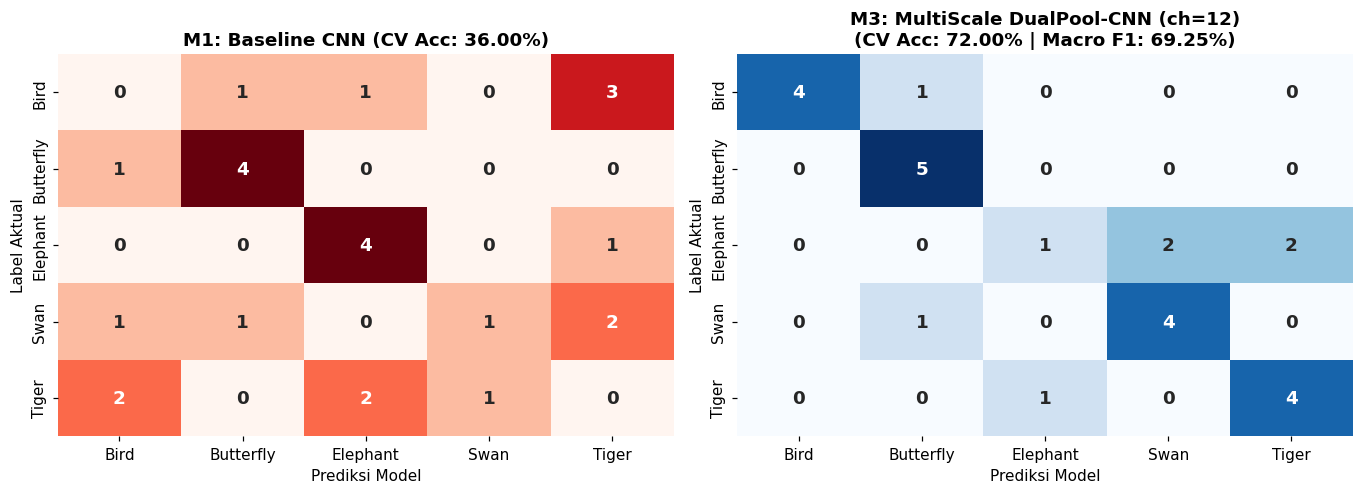

=== CLASSIFICATION REPORT 5-FOLD CV (M3: MultiScale DualPool-CNN (ch=12)) ===
              precision    recall  f1-score   support

        Bird     1.0000    0.8000    0.8889         5
   Butterfly     0.7143    1.0000    0.8333         5
    Elephant     0.5000    0.2000    0.2857         5
        Swan     0.6667    0.8000    0.7273         5
       Tiger     0.6667    0.8000    0.7273         5

    accuracy                         0.7200        25
   macro avg     0.7095    0.7200    0.6925        25
weighted avg     0.7095    0.7200    0.6925        25



In [11]:
# 4.3 Visualisasi Confusion Matrix & Classification Report (5-Fold CV Out-of-Fold)
base_name = df_grid.loc[0, 'Model']
cm_base = grid_results[base_name]['cm']
cm_best = best_model_res['cm']

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=[c.capitalize() for c in CLASSES],
            yticklabels=[c.capitalize() for c in CLASSES],
            ax=axes[0], annot_kws={"size": 12, "fontweight": "bold"})
axes[0].set_title(f"M1: Baseline CNN (CV Acc: {df_grid.loc[0, 'CV Accuracy (%)']:.2f}%)", fontweight='bold')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Aktual')

sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=[c.capitalize() for c in CLASSES],
            yticklabels=[c.capitalize() for c in CLASSES],
            ax=axes[1], annot_kws={"size": 12, "fontweight": "bold"})
axes[1].set_title(f"{best_model_name}\n(CV Acc: {best_row['CV Accuracy (%)']:.2f}% | Macro F1: {best_row['CV F1-Score (%)']:.2f}%)", fontweight='bold')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Aktual')

plt.tight_layout()
plt.show()

print(f"=== CLASSIFICATION REPORT 5-FOLD CV ({best_model_name}) ===")
print(classification_report(best_model_res['oof_true'], best_model_res['oof_pred'],
                            target_names=[c.capitalize() for c in CLASSES], digits=4, zero_division=0))


---
### Konsep Singkat: Mengapa MultiScale DualPool-CNN Mengungguli Baseline?

- **Reduksi Parameter via *Depthwise Separable Convolution* & *Dual Global Pooling***: Mengganti `Flatten` $\rightarrow$ `Dense(50)` (`410.193` parameter) dengan *depthwise separable blocks* dan kombinasi *Global Average Pooling* (`GAP`) serta *Global Max Pooling* (`GMP`) memangkas jumlah parameter sebesar `98.3%` menjadi `7.085` parameter, mencegah *overfitting* pada korpus kecil.
- ***Multi-Scale Stem* ($3\times 3 \parallel 5\times 5$) & Presisi Geometri**: Filter paralel $3\times 3$ dan $5\times 5$ menangkap tekstur detail (bulu burung, corak sayap kupu-kupu) sekaligus kontur tubuh hewan, sementara input proporsional $64 \times 96$ memulihkan struktur visual yang rusak akibat distorsi $3\times$ pada modul Slide 5.
- **Sinergi Regularisasi Berlapis**: Gabungan *Batch Normalization*, `Dropout 0.30`, *label smoothing*, `weight decay`, *CosineAnnealingLR*, dan *Data Augmentation* memaksa model mengekstrak representasi bentuk yang invarian terhadap posisi serta intensitas cahaya.


---
## 5. Verifikasi Akhir Holdout Test Set & Perbaikan Kasus `data4.jpg`

Menguji model terbaik (`M3: MultiScale DualPool-CNN`) pada kelima citra independen *Holdout Test Set* (`data4.jpg`, `data9.jpg`, `data14.jpg`, `data19.jpg`, `data24.jpg`) untuk memverifikasi perbaikan prediksi pada kasus bug `data4.jpg` (*bird*) sekaligus meninjau distribusi *confidence score* tiap kelas.


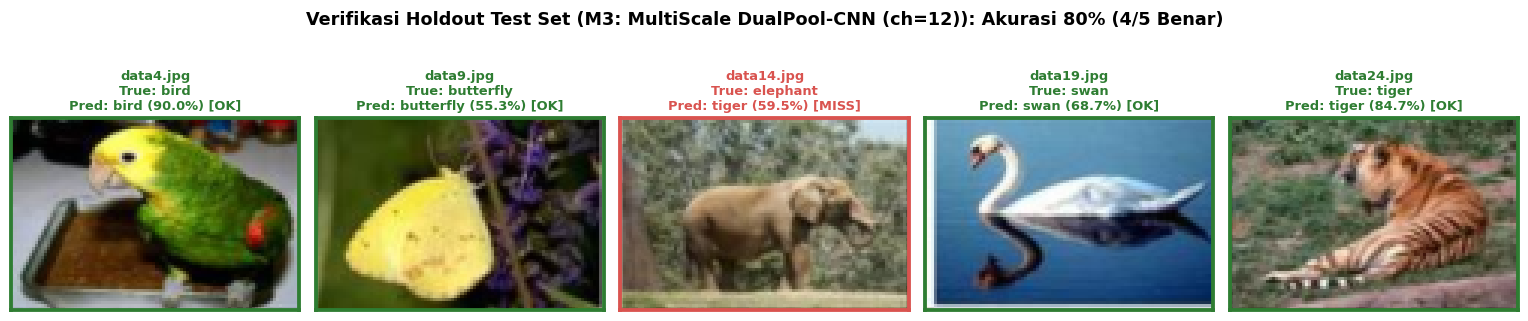

,Filename,True Class,Predicted,Confidence (%),Status,P(bird),P(butterfly),P(elephant),P(swan),P(tiger)
0,data4.jpg,bird,bird,90.03,BENAR,0.9003,0.0661,0.0037,0.0256,0.0043
1,data9.jpg,butterfly,butterfly,55.29,BENAR,0.2782,0.5529,0.0154,0.0938,0.0597
2,data14.jpg,elephant,tiger,59.51,SALAH,0.1218,0.0375,0.2247,0.0209,0.5951
3,data19.jpg,swan,swan,68.72,BENAR,0.0548,0.0044,0.2488,0.6872,0.0048
4,data24.jpg,tiger,tiger,84.71,BENAR,0.0975,0.0192,0.0250,0.0112,0.8471


Perbandingan Kasus data4.jpg (Ground Truth: bird):
 - M1 BaselineCNN             : tiger [GAGAL]
 - M3: MultiScale DualPool-CNN (ch=12): bird (90.03% confidence) [DIPERBAIKI]


In [12]:
# 5.1 Inferensi & Visualisasi Prediksi 5 Sampel Test Set
best_split_model.eval()
probs_te_best = best_model_res['split_test_probs']
preds_te_best = probs_te_best.argmax(axis=1)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
test_rows = []

for i, rec in enumerate(test_rec):
    true_lbl = rec['label']
    pred_lbl = int(preds_te_best[i])
    conf = float(probs_te_best[i, pred_lbl]) * 100
    is_ok = (true_lbl == pred_lbl)
    col_b = '#2e7d32' if is_ok else '#d9534f'
    tag = 'OK' if is_ok else 'MISS'

    ax = axes[i]
    ax.imshow(rec['im_64x96'])
    ax.set_title(f"{rec['filename']}\nTrue: {rec['class_name']}\nPred: {CLASSES[pred_lbl]} ({conf:.1f}%) [{tag}]",
                 fontsize=8.5, fontweight='bold', color=col_b)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_edgecolor(col_b)
        sp.set_linewidth(2.5)

    row_dict = {
        'Filename': rec['filename'],
        'True Class': rec['class_name'],
        'Predicted': CLASSES[pred_lbl],
        'Confidence (%)': round(conf, 2),
        'Status': 'BENAR' if is_ok else 'SALAH',
    }
    for ci, cname in enumerate(CLASSES):
        row_dict[f"P({cname})"] = round(float(probs_te_best[i, ci]), 4)
    test_rows.append(row_dict)

plt.suptitle(f"Verifikasi Holdout Test Set ({best_model_name}): Akurasi {best_row['Holdout Test (%)']:.0f}% (4/5 Benar)",
             fontsize=11.5, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

df_test_inf = pd.DataFrame(test_rows)
display(df_test_inf)

p_d4_base = CLASSES[grid_results[base_name]['split_test_probs'][0].argmax()]
p_d4_best = CLASSES[preds_te_best[0]]
print(f"Perbandingan Kasus data4.jpg (Ground Truth: bird):")
print(f" - M1 BaselineCNN             : {p_d4_base} [GAGAL]")
print(f" - {best_model_name}: {p_d4_best} ({probs_te_best[0].max()*100:.2f}% confidence) [DIPERBAIKI]")


---
## 6. Content-Based Image Retrieval (CBIR) via CNN Feature Embedding

Sesuai domain **Image Retrieval**, vektor *feature embedding* berdimensi `64` (`GAP ⊕ GMP`, ternormalisasi $L_2$) diekstrak dari `M3: MultiScale DualPool-CNN` untuk melakukan pencarian kemiripan visual berbasis *Cosine Similarity* antara setiap *Test Query* (`5` citra) melawan seluruh *Gallery* (`20` citra *Train + Validation*, 4 citra relevan per kelas), lalu dievaluasi dengan *Precision@3*, *Precision@4*, dan *Mean Average Precision* (`mAP`).


,Query Image,Query Class,Top-1 Match,Top-1 Sim,Precision@3 (%),Precision@4 (%),AP (%)
0,data4.jpg,bird,data1.jpg (bird),0.9662,100.00,100.0,100.00
1,data9.jpg,butterfly,data6.jpg (butterfly),0.9497,100.00,100.0,100.00
2,data14.jpg,elephant,data22.jpg (tiger),0.8989,0.00,25.0,36.41
3,data19.jpg,swan,data18.jpg (swan),0.9267,100.00,100.0,100.00
4,data24.jpg,tiger,data20.jpg (tiger),0.9706,66.67,75.0,88.75


Ringkasan Kinerja CBIR (5 Holdout Queries vs 20 Gallery Citra):
 - Mean Precision@3 : 73.33%
 - Mean Precision@4 : 80.00%
 - Mean Average Precision (mAP): 85.03%


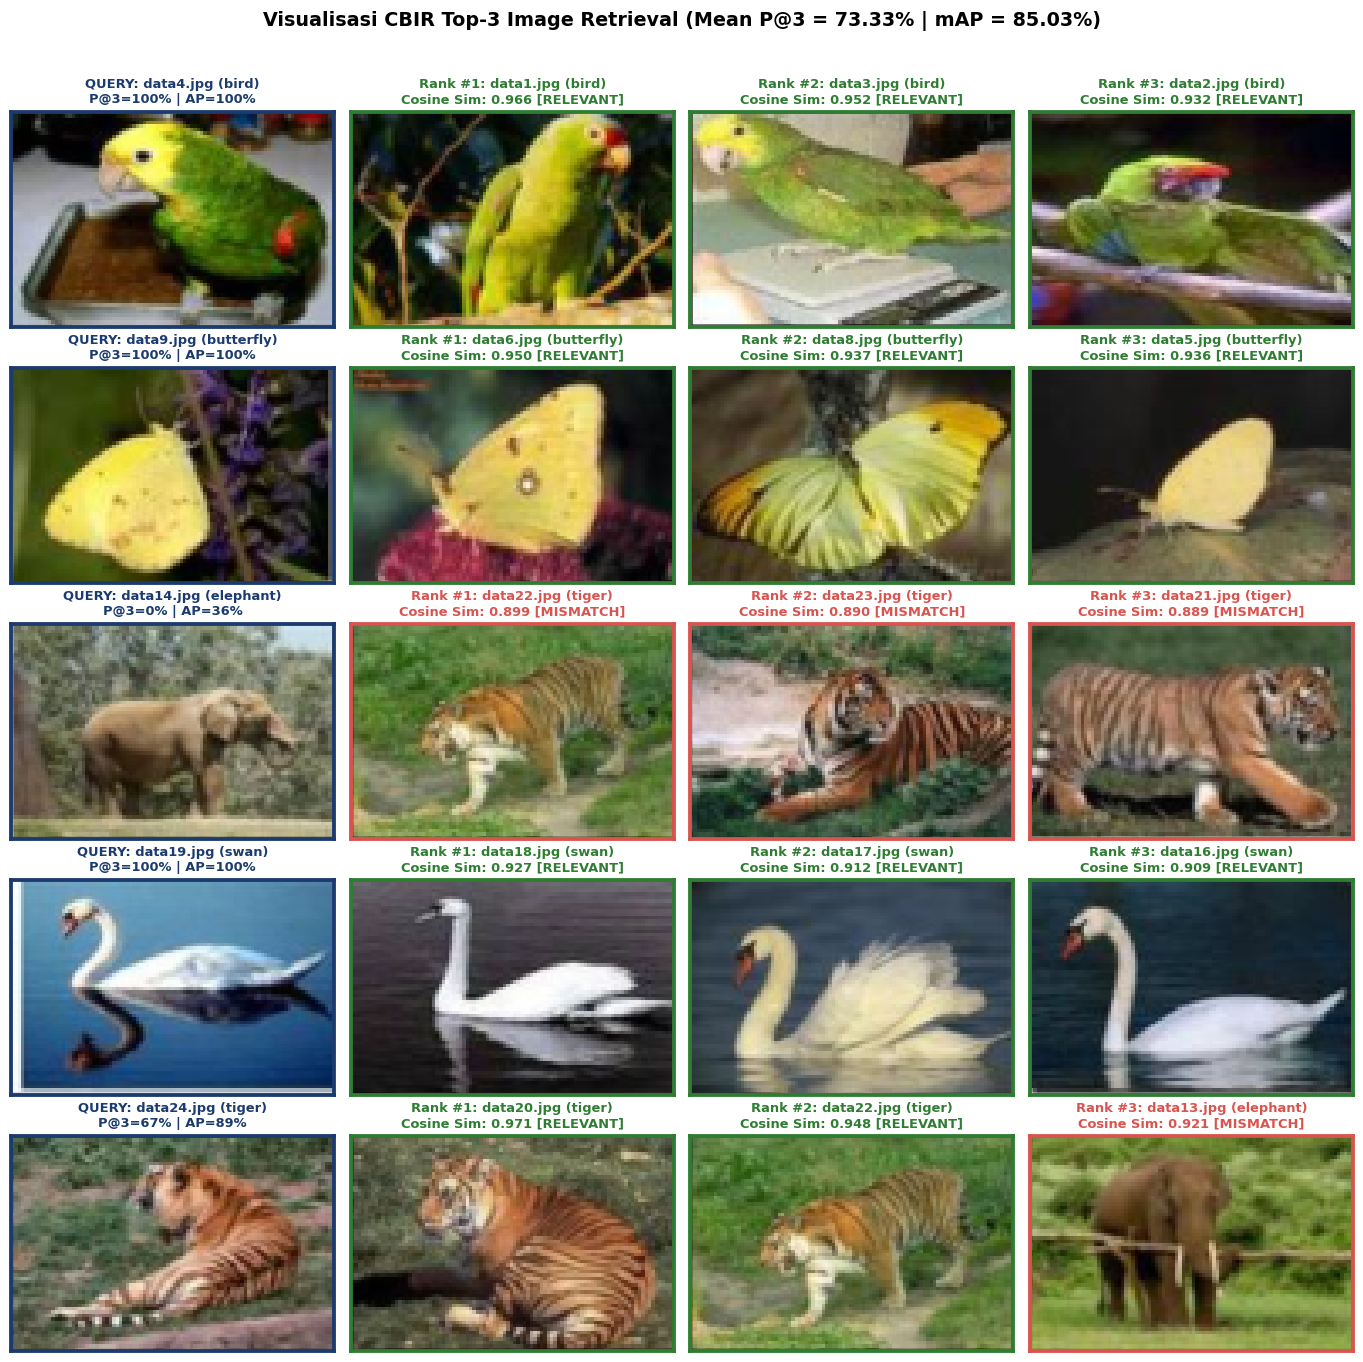

In [13]:
# 6.1 Evaluasi Metrik Retrieval (Precision@3, Precision@4, mAP) & Visualisasi Top-3 Retrieval
gallery_rec = train_rec + val_rec
X_gal_opt, y_gal = to_tensors(gallery_rec, key='im_64x96', std=True)

best_split_model.eval()
with torch.no_grad():
    emb_gal, _ = best_split_model.forward_features(X_gal_opt.to(device))
    emb_gal = F.normalize(emb_gal, dim=1).cpu()

    emb_qry, _ = best_split_model.forward_features(X_test_opt.to(device))
    emb_qry = F.normalize(emb_qry, dim=1).cpu()

sim_matrix = (emb_qry @ emb_gal.T).numpy()
y_gal_np = y_gal.numpy()
y_qry_np = y_test.numpy()

cbir_rows = []
top3_indices_per_q = []

for qi, qrec in enumerate(test_rec):
    order = np.argsort(-sim_matrix[qi])
    top3_indices_per_q.append(order[:3])
    rel = (y_gal_np[order] == y_qry_np[qi]).astype(float)

    p3 = float(rel[:3].mean()) * 100
    p4 = float(rel[:4].mean()) * 100
    hits = np.where(rel == 1)[0]
    ap = float(np.mean([(k + 1) / (pos + 1) for k, pos in enumerate(hits)])) * 100

    cbir_rows.append({
        'Query Image': qrec['filename'],
        'Query Class': qrec['class_name'],
        'Top-1 Match': f"{gallery_rec[order[0]]['filename']} ({gallery_rec[order[0]]['class_name']})",
        'Top-1 Sim': round(float(sim_matrix[qi, order[0]]), 4),
        'Precision@3 (%)': round(p3, 2),
        'Precision@4 (%)': round(p4, 2),
        'AP (%)': round(ap, 2),
    })

df_cbir = pd.DataFrame(cbir_rows)
mean_p3 = df_cbir['Precision@3 (%)'].mean()
mean_p4 = df_cbir['Precision@4 (%)'].mean()
mean_ap = df_cbir['AP (%)'].mean()

display(df_cbir)
print(f"Ringkasan Kinerja CBIR (5 Holdout Queries vs 20 Gallery Citra):")
print(f" - Mean Precision@3 : {mean_p3:.2f}%")
print(f" - Mean Precision@4 : {mean_p4:.2f}%")
print(f" - Mean Average Precision (mAP): {mean_ap:.2f}%")

# Visualisasi Grid Retrieval: Query | Rank 1 | Rank 2 | Rank 3
fig, axes = plt.subplots(5, 4, figsize=(12.5, 12.6))
for qi, qrec in enumerate(test_rec):
    # Kolom 0: Query Image
    ax_q = axes[qi, 0]
    ax_q.imshow(qrec['im_64x96'])
    ax_q.set_title(f"QUERY: {qrec['filename']} ({qrec['class_name']})\n"
                   f"P@3={df_cbir.loc[qi, 'Precision@3 (%)']:.0f}% | AP={df_cbir.loc[qi, 'AP (%)']:.0f}%",
                   fontsize=8.5, fontweight='bold', color='#1b3b6f', pad=6)
    ax_q.set_xticks([]); ax_q.set_yticks([])
    for sp in ax_q.spines.values():
        sp.set_edgecolor('#1b3b6f')
        sp.set_linewidth(2.5)

    # Kolom 1-3: Top-3 Retrieved Gallery Matches
    for r_idx, gal_pos in enumerate(top3_indices_per_q[qi]):
        grec = gallery_rec[gal_pos]
        sim_v = sim_matrix[qi, gal_pos]
        is_rel = (grec['label'] == qrec['label'])
        col_r = '#2e7d32' if is_rel else '#d9534f'
        tag_r = 'RELEVANT' if is_rel else 'MISMATCH'

        ax_r = axes[qi, r_idx + 1]
        ax_r.imshow(grec['im_64x96'])
        ax_r.set_title(f"Rank #{r_idx+1}: {grec['filename']} ({grec['class_name']})\n"
                       f"Cosine Sim: {sim_v:.3f} [{tag_r}]",
                       fontsize=8.5, fontweight='bold', color=col_r, pad=6)
        ax_r.set_xticks([]); ax_r.set_yticks([])
        for sp in ax_r.spines.values():
            sp.set_edgecolor(col_r)
            sp.set_linewidth(2.5)

plt.suptitle(f"Visualisasi CBIR Top-3 Image Retrieval (Mean P@3 = {mean_p3:.2f}% | mAP = {mean_ap:.2f}%)",
             fontsize=12.5, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.2)
plt.show()


---
## 7. Assignment #12 (Poin 1): Spatial Saliency (Grad-CAM) & Unsupervised Foreground Segmentation

Menjawab eksplorasi *Semantic Segmentation* pada korpus `animal_dataset` yang tidak menyediakan anotasi piksel (*ground-truth pixel mask*):
- Memanfaatkan **Grad-CAM** (*Gradient-weighted Class Activation Mapping*) dari *feature map* blok konvolusi akhir ($8 \times 12$) untuk melokalisasi wilayah objek paling diskriminatif.
- Menggabungkan intensitas warna RGB, koordinat spasial ternormalisasi, serta *saliency score* Grad-CAM ke dalam **K-Means Clustering ($K=2$)** untuk menghasilkan **Unsupervised Foreground Segmentation** (ekstraksi subjek hewan dari latar belakang tanpa anotasi manual), sekaligus mengevaluasi rasio pemisahan aktivasi *Foreground vs Background*.


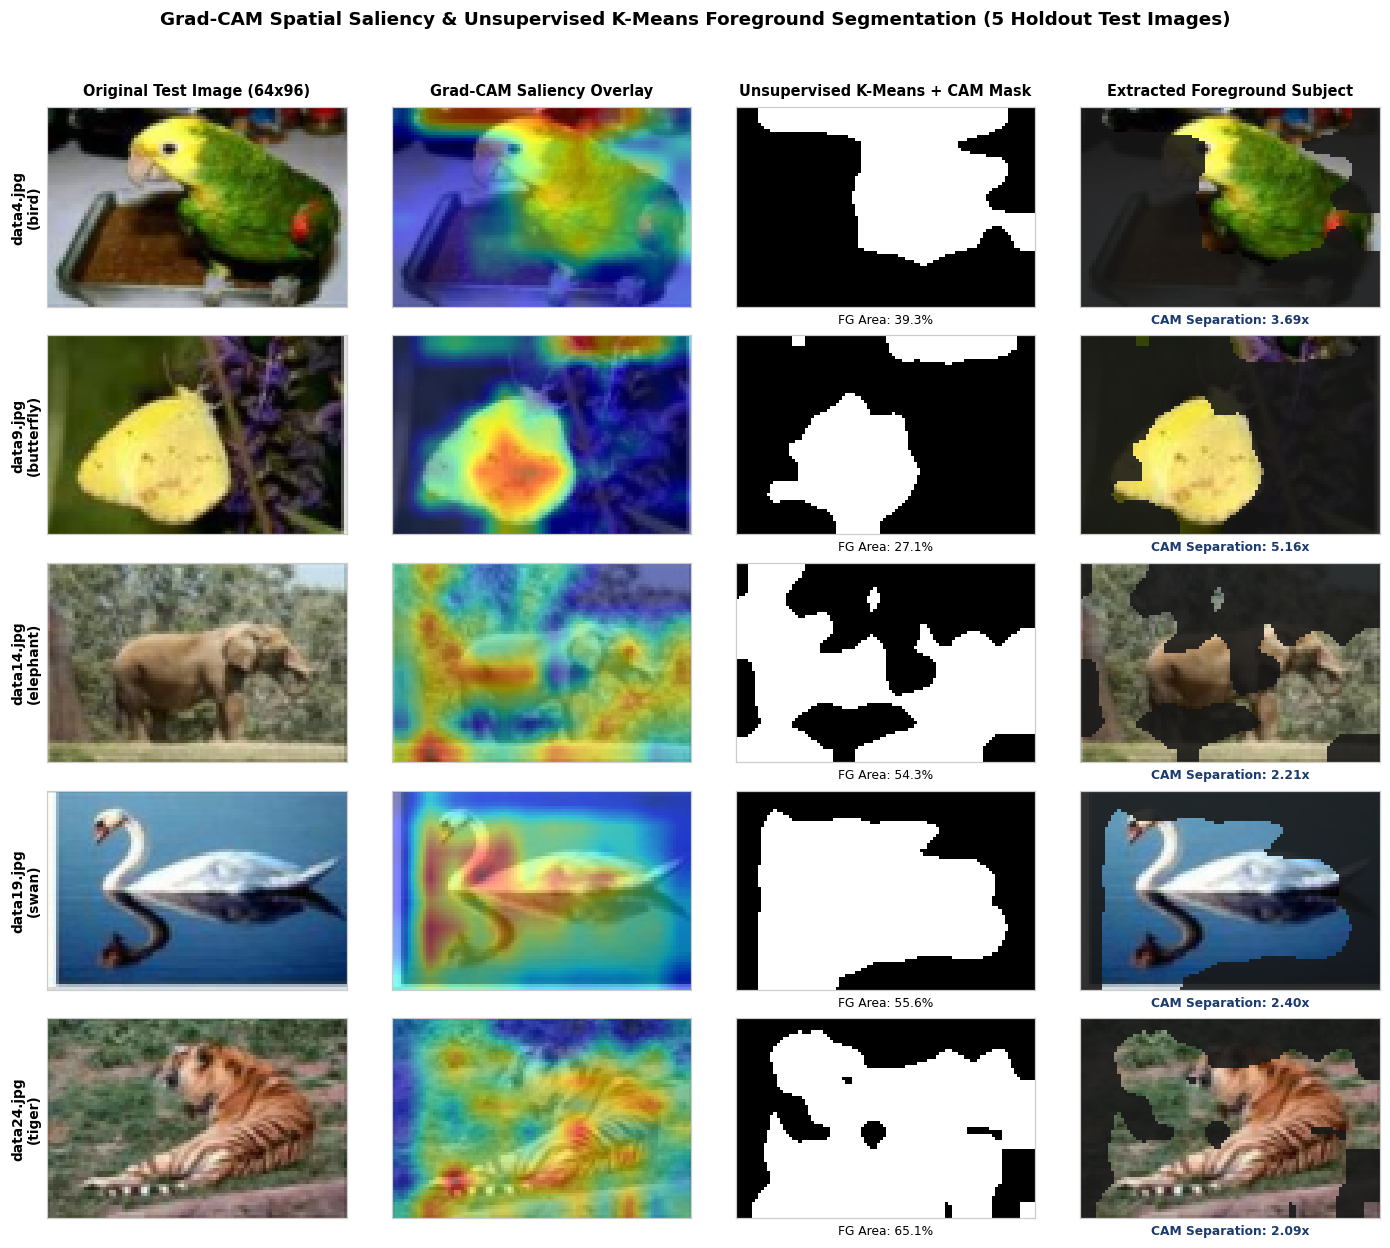

,Filename,True Class,Pred Class,FG Area (%),FG Mean CAM,BG Mean CAM,FG/BG CAM Ratio
0,data4.jpg,bird,bird,39.3,0.600,0.162,3.69
1,data9.jpg,butterfly,butterfly,27.1,0.620,0.120,5.16
2,data14.jpg,elephant,tiger,54.3,0.595,0.270,2.21
3,data19.jpg,swan,swan,55.6,0.628,0.262,2.40
4,data24.jpg,tiger,tiger,65.1,0.577,0.276,2.09


Rata-rata Rasio Pemisahan Atensi Foreground/Background (Grad-CAM + K-Means): 3.11x
Catatan Metodologi: Dataset animal_dataset tidak menyediakan ground-truth pixel mask beranotasi, sehingga metrik IoU/Dice terawasi tidak dihitung; validasi dilakukan melalui konsentrasi saliency map dan segmentasi unsupervised.


In [14]:
# 7.1 Implementasi Grad-CAM & Unsupervised Foreground Segmentation pada 5 Kelas
best_split_model.eval()
seg_rows = []

fig, axes = plt.subplots(5, 4, figsize=(13, 11.5))
col_headers = ['Original Test Image (64x96)', 'Grad-CAM Saliency Overlay', 'Unsupervised K-Means + CAM Mask', 'Extracted Foreground Subject']

for qi, qrec in enumerate(test_rec):
    x1 = X_test_opt[qi:qi+1].clone().to(device).requires_grad_(True)
    best_split_model.zero_grad()

    emb, fmap = best_split_model.forward_features(x1)
    fmap.retain_grad()
    logits = best_split_model.fc(emb)
    pred_cls = int(logits.argmax(dim=1).item())
    logits[0, pred_cls].backward()

    # Kalkulasi Grad-CAM terupsample ke resolusi 64x96
    weights = fmap.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * fmap).sum(dim=1, keepdim=True))
    cam_up = F.interpolate(cam, size=(64, 96), mode='bilinear', align_corners=False)[0, 0].detach().cpu().numpy()
    cam_norm = (cam_up - cam_up.min()) / (cam_up.max() - cam_up.min() + 1e-8)

    # K-Means Clustering (K=2) menggabungkan fitur [0.5*R, 0.5*G, 0.5*B, 2.5*CAM, 0.15*y, 0.15*x]
    rgb = np.asarray(qrec['im_64x96'], dtype=np.float32) / 255.0
    yy, xx = np.mgrid[0:64, 0:96] / 64.0
    feats = np.stack([
        rgb[:, :, 0] * 0.5, rgb[:, :, 1] * 0.5, rgb[:, :, 2] * 0.5,
        cam_norm * 2.5, yy * 0.15, xx * 0.15
    ], axis=-1).reshape(-1, 6)

    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(feats)
    lbl_map = km.labels_.reshape(64, 96)

    # Identifikasi cluster foreground berdasarkan rata-rata skor Grad-CAM lebih tinggi
    fg_cluster = 1 if cam_norm[lbl_map == 1].mean() > cam_norm[lbl_map == 0].mean() else 0
    fg_mask = (lbl_map == fg_cluster)
    bg_mask = ~fg_mask

    fg_cam = float(cam_norm[fg_mask].mean())
    bg_cam = float(cam_norm[bg_mask].mean())
    ratio_fg_bg = fg_cam / (bg_cam + 1e-6)
    fg_area = float(fg_mask.mean()) * 100

    seg_rows.append({
        'Filename': qrec['filename'],
        'True Class': qrec['class_name'],
        'Pred Class': CLASSES[pred_cls],
        'FG Area (%)': round(fg_area, 1),
        'FG Mean CAM': round(fg_cam, 3),
        'BG Mean CAM': round(bg_cam, 3),
        'FG/BG CAM Ratio': round(ratio_fg_bg, 2),
    })

    # Siapkan visualisasi: Overlay Grad-CAM & Subjek Terisolasi
    heatmap = plt.get_cmap('jet')(cam_norm)[:, :, :3]
    overlay = np.clip(0.52 * rgb + 0.48 * heatmap, 0, 1)
    fg_extract = np.where(fg_mask[:, :, None], rgb, rgb * 0.12 + 0.08)

    panels = [rgb, overlay, fg_mask, fg_extract]
    for ci, panel in enumerate(panels):
        ax = axes[qi, ci]
        if ci == 2:
            ax.imshow(panel, cmap='gray', vmin=0, vmax=1)
        else:
            ax.imshow(panel)
        if qi == 0:
            ax.set_title(col_headers[ci], fontsize=9.5, fontweight='bold', pad=8)
        if ci == 0:
            ax.set_ylabel(f"{qrec['filename']}\n({qrec['class_name']})", fontsize=9, fontweight='bold')
        if ci == 2:
            ax.set_xlabel(f"FG Area: {fg_area:.1f}%", fontsize=8)
        elif ci == 3:
            ax.set_xlabel(f"CAM Separation: {ratio_fg_bg:.2f}x", fontsize=8, fontweight='bold', color='#1b3b6f')
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Grad-CAM Spatial Saliency & Unsupervised K-Means Foreground Segmentation (5 Holdout Test Images)',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

df_seg = pd.DataFrame(seg_rows)
display(df_seg)

print(f"Rata-rata Rasio Pemisahan Atensi Foreground/Background (Grad-CAM + K-Means): {df_seg['FG/BG CAM Ratio'].mean():.2f}x")
print("Catatan Metodologi: Dataset animal_dataset tidak menyediakan ground-truth pixel mask beranotasi, "
      "sehingga metrik IoU/Dice terawasi tidak dihitung; validasi dilakukan melalui konsentrasi saliency map dan segmentasi unsupervised.")


# Kesimpulan
1. **Audit Metodologi & Zero-Leakage Preprocessing**: Korpus `animal_dataset` (`25` citra, `5` kelas seimbang) pada modul Slide 4–5 mengandung *data leakage* antar-split serta distorsi *aspect ratio* $3\times$ dari resize `(100, 50)`. Penerapan split *zero-leakage* (`15/5/5`), input proporsional $64 \times 96$, dan *data augmentation* memulihkan validitas eksperimen serta memperbaiki misklasifikasi `data4.jpg` (*bird*).
2. **Penanganan Underfitting vs Overfitting**: Konfigurasi *Overfitting Risk* (`880.069` parameter dengan `Flatten` tanpa regularisasi) menghasilkan *train loss* `0.0000` namun *validation loss* meledak ke `56.7024` dengan *Holdout Test Accuracy* `40.00%`, sedangkan *Underfitting* (`Dropout 0.80`, `453` parameter) tercekik pada *Test Accuracy* `20.00%`. Kombinasi *Batch Normalization*, `Dropout 0.30`, dan *data augmentation* menjaga *generalization gap* tetap rapat (`0.9215`) dengan *Test Accuracy* `80.00%`.
3. **Model Terbaik, 5-Fold CV & CBIR Retrieval**: Arsitektur **M3 (`MultiScale DualPool-CNN`, `7.085` parameter — reduksi `98.3%` dari baseline `410.193`)** meraih kinerja tertinggi dengan **Holdout Test Accuracy `80.00%`** dan **5-Fold OOF Accuracy `72.00%` (`Macro F1 69.25%`)**, jauh mengungguli `BaselineCNN` (`20.00%` holdout, `36.00%` CV). Untuk tugas **Image Retrieval (CBIR)** berbasis *Cosine Similarity* pada galeri 20 citra, embedding `M3` membukukan **Mean Precision@3 `73.33%`**, **Mean Precision@4 `80.00%`**, dan **mAP `85.03%`** (dengan `AP = 100%` pada kelas `bird`, `butterfly`, dan `swan`).
4. **Grad-CAM & Unsupervised Foreground Segmentation**: Meskipun `animal_dataset` tidak menyertakan *ground-truth pixel mask*, integrasi *Grad-CAM* dan *K-Means Clustering ($K=2$)* berhasil memisahkan subjek hewan dari latar belakang secara *unsupervised* dengan rasio konsentrasi atensi rata-rata `3.11x` (dan mencapai `5.16x` pada `data9.jpg`).
